## uppgift 4

Henning Lindh ten Berg & Viggo Östlund
4 november 2026

## a) Matematiskt modell

Vi vill minimera den sammanlagda lastbilstrafiken på vägarna.

Variabeln x[k, i, j] beskriver hur många lastbilar för transportbehov k som kör från nod i till nod j.

Varje transportbehov k har: en startnod, en destinationsnod och ett antal lastbilar som ska transporteras

Målfunktionen minimerar summan av alla lastbilars körda vägsträckor:

minimera summan av vägavståndet gånger antalet lastbilar på varje väg.

För varje transportbehov gäller flödesbalans i varje nod:
- I startnoden lämnar lika många lastbilar som transportbehovet.
- I destinationsnoden anländer lika många lastbilar som transportbehovet.
- I övriga noder måste lika många lastbilar lämna noden som anländer till den.

Färjan mellan nod 2 och 6 har en kapacitet på 2 000 lastbilar per riktning och år.

Alla flöden måste vara större än eller lika med noll.

## a. Indata och nätverk

Här importeras de paket som används i lösningen. Därefter registreras transportbehoven, noderna, vägarna och deras avstånd.

Varje väg läggs in i båda riktningarna, eftersom lastbilar kan köra åt båda håll. Färjan mellan nod 2 och 6 har avståndet 0 eftersom färjetransporten inte räknas som lastbilstrafik på väg.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

#transportbehov:
#(startnod, destinationsnod): antal lastbilar
efterfragan = {
    (1, 2): 900, (1, 3): 750, (1, 4): 40,
    (1, 5): 10,  (1, 6): 600, (1, 7): 550,

    (4, 1): 100, (4, 2): 2000, (4, 3): 1100,
    (4, 5): 150, (4, 6): 1400, (4, 7): 1250,

    (5, 1): 110, (5, 2): 4000, (5, 3): 2200,
    (5, 4): 200, (5, 6): 3300, (5, 7): 2440
}

transportbehov = list(efterfragan.keys())
noder = [1, 2, 3, 4, 5, 6, 7]

#vägar med avstånd i svenska mil
vagar = [
    (1, 2, 3.5),
    (2, 3, 3.0),
    (3, 4, 5.0),
    (4, 5, 25.0),
    (5, 6, 4.0),
    (6, 7, 2.5)
]

#alla vägar finns i båda riktningar
bagar = []

for start, slut, avstand in vagar:
    bagar.append((start, slut, avstand))
    bagar.append((slut, start, avstand))

#färjan mellan nod 2 och 6
bagar.append((2, 6, 0.0))
bagar.append((6, 2, 0.0))

antal_bagar = len(bagar)
antal_transportbehov = len(transportbehov)

bag_index = {
    (start, slut): index
    for index, (start, slut, avstand) in enumerate(bagar)
}

## Skapa optimeringsmodellen

Funktionen nedan bygger och löser transportmodellen.

Målet är att minimera lastbilarnas totala körsträcka. Funktionen kan användas både för olika antal färjor och för olika kapacitet på vägen mellan nod 2 och 3.

In [ ]:
def los_transportproblem(antal_farjor=1, kapacitet_23=None):

    #målfunktion:
    #minimera lastbilarnas sammanlagda körsträcka i svenska mil
    c = np.tile(
        [avstand for start, slut, avstand in bagar],
        antal_transportbehov
    )

    A_eq = []
    b_eq = []

    #flödesbalans för varje transportbehov i varje nod
    for k, (startnod, destinationsnod) in enumerate(transportbehov):

        for nod in noder:
            rad = np.zeros(antal_transportbehov * antal_bagar)

            for a, (start, slut, avstand) in enumerate(bagar):

                if start == nod:
                    rad[k * antal_bagar + a] = 1

                elif slut == nod:
                    rad[k * antal_bagar + a] = -1

            A_eq.append(rad)

            if nod == startnod:
                b_eq.append(efterfragan[(startnod, destinationsnod)])

            elif nod == destinationsnod:
                b_eq.append(-efterfragan[(startnod, destinationsnod)])

            else:
                b_eq.append(0)

    A_ub = []
    b_ub = []

    #varje färja klarar 2 000 lastbilar per riktning
    fargekapacitet = 2000 * antal_farjor

    for rutt in [(2, 6), (6, 2)]:
        rad = np.zeros(antal_transportbehov * antal_bagar)
        a = bag_index[rutt]

        for k in range(antal_transportbehov):
            rad[k * antal_bagar + a] = 1

        A_ub.append(rad)
        b_ub.append(fargekapacitet)

    #kapacitetsbegränsning på vägen mellan nod 2 och 3
    if kapacitet_23 is not None:

        for rutt in [(2, 3), (3, 2)]:
            rad = np.zeros(antal_transportbehov * antal_bagar)
            a = bag_index[rutt]

            for k in range(antal_transportbehov):
                rad[k * antal_bagar + a] = 1

            A_ub.append(rad)
            b_ub.append(kapacitet_23)

    resultat = linprog(
        c,
        A_ub=A_ub,
        b_ub=b_ub,
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=(0, None),
        method="highs"
    )

    return resultat

## b. Lösning med en färja

Här löses modellen med en färja. Färjan kan transportera högst 2 000 lastbilar per år i vardera riktning.

In [3]:
resultat = los_transportproblem(antal_farjor=1)

print("Hittades en optimal lösning?", resultat.success)
print("Minsta möjliga lastbilstrafik:", resultat.fun, "fordonsmil per år")

Hittades en optimal lösning? True
Minsta möjliga lastbilstrafik: 280770.0 fordonsmil per år


## Kontroll av färjekapaciteten

Här beräknas hur många lastbilar som faktiskt använder färjan i varje riktning.

Det visar om färjekapaciteten används fullt ut eller om det finns ledig kapacitet.

In [4]:
def totalt_flode(resultat, rutt):
    a = bag_index[rutt]

    return sum(
        resultat.x[k * antal_bagar + a]
        for k in range(antal_transportbehov)
    )

print("Färja 2 till 6:", totalt_flode(resultat, (2, 6)))
print("Färja 6 till 2:", totalt_flode(resultat, (6, 2)))

Färja 2 till 6: 2000.0
Färja 6 till 2: 2000.0


## resultat för en färja

Med en färja blir den minsta möjliga lastbilstrafiken 280 770 fordonsmil per år.

Färjan används fullt ut i båda riktningarna: 2 000 lastbilar från nod 2 till nod 6, 2 000 lastbilar från nod 6 till nod 2

det visar att färjekapaciteten är en begränsande faktor i lösningen.

## c. Analys av fler färjor

Här löses modellen för mellan noll och sex färjor.

Syftet är att se hur den totala lastbilstrafiken förändras när färjekapaciteten ökar.

In [5]:
resultat_farjor = []

for antal_farjor in range(0, 7):
    resultat = los_transportproblem(antal_farjor=antal_farjor)

    resultat_farjor.append({
        "Antal färjor": antal_farjor,
        "Lastbilstrafik": resultat.fun
    })

tabell_farjor = pd.DataFrame(resultat_farjor)
display(tabell_farjor)

,Antal färjor,Lastbilstrafik
0,0,399250.0
1,1,280770.0
2,2,182810.0
3,3,136150.0
4,4,126420.0
5,5,126420.0
6,6,126420.0


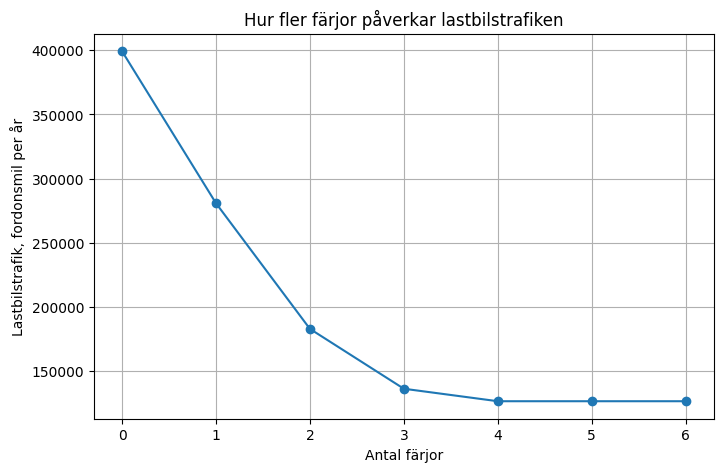

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabell_farjor["Antal färjor"],
    tabell_farjor["Lastbilstrafik"],
    marker="o"
)

plt.xlabel("Antal färjor")
plt.ylabel("Lastbilstrafik, fordonsmil per år")
plt.title("Hur fler färjor påverkar lastbilstrafiken")
plt.grid()
plt.show()

## Resultat när antalet färjor ökar

Utan färja blir den sammanlagda lastbilstrafiken 399 250 fordonsmil per år.

När antalet färjor ökar minskar lastbilstrafiken, eftersom fler lastbilar kan transporteras över bukten i stället för att köra runt den.

Fyra färjor är maximalt användbara. Vid fler än fyra färjor förändras inte lösningen längre, eftersom färjekapaciteten då inte längre är begränsningen.

Med fyra färjor blir den minsta möjliga lastbilstrafiken 126 420 fordonsmil per år.

## d. Minskad kapacitet mellan nod 2 och 3

Här undersöks vad som händer om vägen mellan nod 2 och 3 får en begränsad kapacitet.

Kapaciteten sätts lika stor i båda riktningarna: från 2 till 3 och från 3 till 2.

In [7]:
ursprunglig_losning = los_transportproblem(antal_farjor=1).fun

resultat_kapacitet = []

for kapacitet in range(4500, 6001, 50):
    resultat = los_transportproblem(
        antal_farjor=1,
        kapacitet_23=kapacitet
    )

    resultat_kapacitet.append({
        "Kapacitet per riktning": kapacitet,
        "Lastbilstrafik": resultat.fun
    })

tabell_kapacitet = pd.DataFrame(resultat_kapacitet)
display(tabell_kapacitet)

,Kapacitet per riktning,Lastbilstrafik
0,4500,292320.0
1,4550,291270.0
2,4600,290220.0
3,4650,289170.0
4,4700,288120.0
5,4750,287070.0
6,4800,286020.0
7,4850,284970.0
8,4900,283920.0
9,4950,282870.0


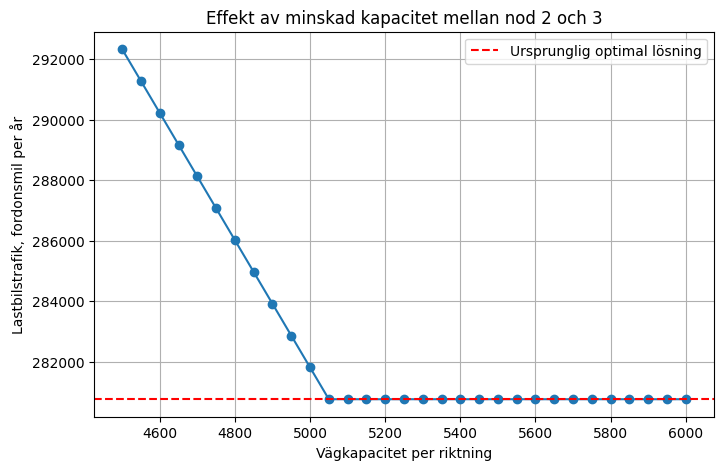

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabell_kapacitet["Kapacitet per riktning"],
    tabell_kapacitet["Lastbilstrafik"],
    marker="o"
)

plt.axhline(
    ursprunglig_losning,
    color="red",
    linestyle="--",
    label="Ursprunglig optimal lösning"
)

plt.xlabel("Vägkapacitet per riktning")
plt.ylabel("Lastbilstrafik, fordonsmil per år")
plt.title("Effekt av minskad kapacitet mellan nod 2 och 3")
plt.legend()
plt.grid()
plt.show()

## Resultat för minskad vägkapacitet

När kapaciteten mellan nod 2 och 3 minskas måste fler lastbilar välja längre vägar. Då ökar den sammanlagda lastbilstrafiken.

Kapaciteten behöver vara minst 5 050 lastbilar per riktning och år för att den ursprungliga lösningen inte ska påverkas.

Vid denna kapacitet är den totala lastbilstrafiken fortfarande 280 770 fordonsmil per år.